# xG Regression

In [9]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
#from functools import cache
import warnings

NUM_OF_COUNTRIES = 5
NUM_OF_SEASONS = 25
NUM_OF_MATCHES = 9130
NUM_OF_MATCHES_IN_A_SEASON = 1826
SEED = 1893

np.random.seed(SEED)
warnings.filterwarnings('ignore')


In [10]:
def score_from_amount_and_diff(amount, diff):
    if diff < 0:
        home_score = (amount + diff) / 2
        away_score = home_score - diff
    else:
        away_score = (amount - diff) / 2
        home_score = away_score + diff

    # cut excess floating numbers
    if (home_score - int(home_score)) == 0 and (away_score - int(away_score)) == 0:
        home_score = int(home_score)
        away_score = int(away_score)

    return home_score, away_score


def print_formatted_pred_score(country, season, matchnumber, ht_name, at_name, ht_pred_score, at_pred_score, ht_actual_score, at_actual_score):
    print("%4s %3s %3s %20s %20s %15s | %6s" %
          (country, season, matchnumber, ht_name, at_name,
           str(ht_pred_score)[0:4] + ":" + str(at_pred_score)[0:4],
           f"{ht_actual_score}:{at_actual_score}"))


def closed_form_solution(X, y):
    # alternative: np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))
    return np.linalg.solve(np.dot(X.T, X), np.dot(X.T, y))


def h(X, w):
    return np.matmul(X, w)[0]


In [11]:
df_matches = pd.read_csv('matches_xg.csv', sep=';')
df_matches['bias'] = 1

noise = np.random.normal(0, 0.01, df_matches.shape[0] * 10)

for index, row in df_matches.iterrows():
    # ht
    if row["ht_curr_eff_chancediff"] == 0:
        df_matches.at[index, "ht_curr_eff_chancediff"] = noise[index]
    if row["ht_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "ht_past_chancediff_combined"] = noise[df_matches.shape[0] + index]
    if row["ht_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 2 + index]
    if row["ht_past_chanceamount"] == 0:
        df_matches.at[index,
                      "ht_past_chanceamount"] = noise[df_matches.shape[0] * 3 + index]
    # at
    if row["at_curr_eff_chancediff"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chancediff"] = noise[df_matches.shape[0] * 4 + index]
    if row["at_past_chancediff_combined"] == 0:
        df_matches.at[index,
                      "at_past_chancediff_combined"] = noise[df_matches.shape[0] * 5 + index]
    if row["at_curr_eff_chanceamount"] == 0:
        df_matches.at[index,
                      "at_curr_eff_chanceamount"] = noise[df_matches.shape[0] * 6 + index]
    if row["at_past_chanceamount"] == 0:
        df_matches.at[index,
                      "at_past_chanceamount"] = noise[df_matches.shape[0] * 7 + index]
    # label
    if row["xg_diff"] == 0:
        df_matches.at[index,
                      "xg_diff"] = noise[df_matches.shape[0] * 8 + index]
    if row["xg_amount"] == 0:
        df_matches.at[index,
                      "xg_amount"] = noise[df_matches.shape[0] * 9 + index]

ga_feature_set = ["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                  "ht_past_chanceamount", "at_past_chanceamount", "bias"]
gd_feature_set = ["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                  "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]
ga_label = ["xg_amount"]
gd_label = ["xg_diff"]

df_matches


,country,season,matchnumber,ht_name,at_name,ht_curr_eff_chancediff,at_curr_eff_chancediff,ht_past_chancediff_combined,at_past_chancediff_combined,ht_curr_eff_chanceamount,...,at_past_chanceamount,ht_market_value_ln_relative,at_market_value_ln_relative,ht_is_promoter,at_is_promoter,xg_amount,xg_diff,actual_goalamount,actual_goaldiff,bias
0,ENG,14,1,Queens Park Rangers,Hull,-0.000107,-0.006322,0.005476,0.002399,-0.006037,...,-0.005316,-0.392415,-0.348740,True,False,3.018240,0.783100,1,-1,1
1,ENG,14,1,Newcastle,Man City,-0.002312,0.004580,0.002748,0.007405,0.008663,...,-0.003893,-0.169272,1.002768,False,False,2.446113,-0.514947,2,-2,1
2,ENG,14,1,Burnley,Chelsea,-0.004361,-0.000947,-0.009217,-0.020822,-0.010237,...,0.010205,-1.140622,1.211651,True,False,2.501101,-1.758819,4,-2,1
3,ENG,14,1,Arsenal,Crystal Palace,0.007917,0.024501,0.008286,0.010394,0.001439,...,0.000835,0.917365,-0.536203,False,False,1.712261,1.395959,3,1,1
4,ENG,14,1,West Ham,Tottenham,0.004695,-0.004871,0.002485,-0.000451,0.001249,...,0.009088,-0.198259,0.606114,False,False,2.870160,0.836040,1,-1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9125,ITA,18,38,Frosinone,Chievo,-4.492426,-4.452152,-3.581579,-1.943421,-2.059192,...,4.508772,-1.394930,-1.394930,True,False,0.585014,0.537046,0,0,1
9126,ITA,18,38,Fiorentina,CFC Genoa,1.172165,-1.286395,1.539474,-1.361842,0.407509,...,4.719298,0.350310,-0.144768,False,False,0.370430,0.221648,0,0,1
9127,ITA,18,38,Bologna,Napoli,-0.932129,5.242267,-1.497368,5.293421,-0.446689,...,8.877193,-0.614771,1.070083,False,False,2.737759,-0.858041,5,1,1
9128,ITA,18,38,Inter,Empoli,2.881676,-3.462648,2.380263,-3.058772,1.042860,...,4.403509,1.024225,-0.738824,False,True,4.515770,0.970270,3,1,1


## general weights

In [12]:
training_data = df_matches.query(f"season <= 17")

X_training_data_ga = training_data[["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                                    "ht_past_chanceamount", "at_past_chanceamount", "bias"]].values
X_training_data_gd = training_data[["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                                    "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]].values

y_training_data_ga = training_data[["xg_amount"]].values
y_training_data_gd = training_data[["xg_diff"]].values

w_ga = closed_form_solution(X_training_data_ga, y_training_data_ga)
w_gd = closed_form_solution(X_training_data_gd, y_training_data_gd)

print("weights goalamount:\n", w_ga)
print("weights goaldiff:\n", w_gd)


weights goalamount:
 [[ 0.07407002]
 [ 0.054184  ]
 [ 0.05254949]
 [-0.02899559]
 [ 2.49674839]]
weights goaldiff:
 [[ 0.07014252]
 [-0.05981954]
 [ 0.01837776]
 [-0.0307462 ]
 [ 0.39221204]
 [-0.40190962]
 [ 0.37518975]]


## weights per matchnumber

In [13]:
ga_weights, gd_weights = [], []
for i in range(1, 39):
    training_data = df_matches.query(f"season <= 17 and matchnumber == {i}")
    X_training_data_ga = training_data[["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                                        "ht_past_chanceamount", "at_past_chanceamount", "bias"]].values
    X_training_data_gd = training_data[["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                                        "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]].values
    y_training_data_ga = training_data[["xg_amount"]].values
    y_training_data_gd = training_data[["xg_diff"]].values

    ga_weights.append(closed_form_solution(
        X_training_data_ga, y_training_data_ga))
    gd_weights.append(closed_form_solution(
        X_training_data_gd, y_training_data_gd))

print("weights goalamount match no 1:\n", ga_weights[0])
print("weights goaldiff match no 1:\n", gd_weights[0])
print("weights goalamount match no 18:\n", ga_weights[17])
print("weights goaldiff match no 18:\n", gd_weights[17])


weights goalamount match no 1:
 [[ 5.79722113]
 [ 6.35704627]
 [ 0.06434245]
 [-0.01171573]
 [ 2.19315822]]
weights goaldiff match no 1:
 [[ 1.09090318]
 [-2.28215872]
 [ 0.1495334 ]
 [ 0.03979616]
 [ 0.56500104]
 [-0.48329276]
 [ 0.23360776]]
weights goalamount match no 18:
 [[ 0.11155696]
 [ 0.03169626]
 [-0.02736795]
 [ 0.04356062]
 [ 2.56107027]]
weights goaldiff match no 18:
 [[ 0.19382949]
 [-0.12564537]
 [ 0.03523579]
 [ 0.00397417]
 [-0.03523559]
 [-0.19839136]
 [ 0.41967887]]


## error general weights

In [14]:
training_data_df, test_data_df = df_matches.query(
    f"season < 18"), df_matches.query(f"season == 18")

xga_squared_error, xgd_squared_error = 0, 0
ga_squared_error, gd_squared_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                      "ht_past_chanceamount", "at_past_chanceamount", "bias"]].values
    X_input_gd = row[["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                      "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]].values

    actual_ht_score, actual_at_score = score_from_amount_and_diff(
        row["actual_goalamount"], row["actual_goaldiff"])
    ga_pred, gd_pred = h(X_input_ga, w_ga), h(X_input_gd, w_gd)
    ht_score_pred, at_score_pred = score_from_amount_and_diff(ga_pred, gd_pred)
    xga_squared_error += np.square(ga_pred - row["xg_amount"])
    xgd_squared_error += np.square(gd_pred - row["xg_diff"])
    ga_squared_error += np.square(ga_pred - row["actual_goalamount"])
    gd_squared_error += np.square(gd_pred - row["actual_goaldiff"])

    print_formatted_pred_score(row["country"], row["season"], row["matchnumber"], row["ht_name"],
                               row["at_name"], ht_score_pred, at_score_pred, actual_ht_score, actual_at_score)
    
print("Squared error x goalamount",
      xga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error x goaldiff", xgd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goalamount", ga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goaldiff", gd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)


 ENG  18   1               Wolves              Everton       1.32:1.21 |    2:2
 ENG  18   1              Watford             Brighton       1.57:1.05 |    2:0
 ENG  18   1          Southampton              Burnley       1.63:1.02 |    0:0
 ENG  18   1            Newcastle            Tottenham       1.09:1.40 |    1:2
 ENG  18   1              Man Utd            Leicester       1.66:0.99 |    2:1
 ENG  18   1              Arsenal             Man City       1.33:1.31 |    0:2
 ENG  18   1         Huddersfield              Chelsea       0.93:1.55 |    0:3
 ENG  18   1               Fulham       Crystal Palace       1.43:1.12 |    0:2
 ENG  18   1          Bournemouth              Cardiff       1.75:0.90 |    2:0
 ENG  18   1            Liverpool             West Ham       1.85:0.89 |    4:0
 ENG  18   2            Tottenham               Fulham       2.39:0.56 |    3:1
 ENG  18   2              Everton          Southampton       1.70:0.87 |    2:1
 ENG  18   2             West Ham       

## error weights per matchnumber

In [15]:
xga_squared_error, xgd_squared_error = 0, 0
ga_squared_error, gd_squared_error = 0, 0

for index, row in test_data_df.iterrows():
    X_input_ga = row[["ht_curr_eff_chanceamount", "at_curr_eff_chanceamount",
                      "ht_past_chanceamount", "at_past_chanceamount", "bias"]].values
    X_input_gd = row[["ht_curr_eff_chancediff", "at_curr_eff_chancediff", "ht_past_chancediff_combined", "at_past_chancediff_combined",
                      "ht_market_value_ln_relative", "at_market_value_ln_relative", "bias"]].values

    ga_pred = h(X_input_ga, ga_weights[int(row["matchnumber"])-1])
    gd_pred = h(X_input_gd,  gd_weights[int(row["matchnumber"])-1])
    xga_squared_error += np.square(ga_pred - row["xg_amount"])
    xgd_squared_error += np.square(gd_pred - row["xg_diff"])
    ga_squared_error += np.square(ga_pred - row["actual_goalamount"])
    gd_squared_error += np.square(gd_pred - row["actual_goaldiff"])

print("Squared error x goalamount",
      xga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error x goaldiff", xgd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goalamount", ga_squared_error / NUM_OF_MATCHES_IN_A_SEASON)
print("Squared error goaldiff", gd_squared_error / NUM_OF_MATCHES_IN_A_SEASON)


Squared error x goalamount 1.199377630278611
Squared error x goaldiff 1.193582353923362
Squared error goalamount 2.762221568836598
Squared error goaldiff 2.603917120325269


## Training error - general weights

In [16]:
do_a_training_error_run = False

if do_a_training_error_run:
    training_error_data = dict()
    xga_squared_training_error, xgd_squared_training_error = 0,0
    ga_squared_training_error, gd_squared_training_error = 0, 0
    prev_matchnumber = 0

    for index, row in training_data_df.iterrows():
        if row["season"] == 14 and row["matchnumber"] == 1:
                ga_pred, gd_pred = 0, 0
        else:
            if int(row["matchnumber"]) > prev_matchnumber:
                curr_training_data_df = training_data_df.query(
                    f"season < {row['season']} or (season == {row['season']} and matchnumber < {row['matchnumber']})")
                X_data_train_ga, X_data_train_gd = curr_training_data_df[
                    ga_feature_set], curr_training_data_df[gd_feature_set]
                y_data_train_ga, y_data_train_gd = curr_training_data_df[
                    ga_label], curr_training_data_df[gd_label]
                curr_ga_weight = closed_form_solution(
                    X_data_train_ga, y_data_train_ga)
                curr_gd_weight = closed_form_solution(
                    X_data_train_gd, y_data_train_ga)

            X_input_ga = row[ga_feature_set].values
            X_input_gd = row[gd_feature_set].values

            ga_pred, gd_pred = h(X_input_ga, curr_ga_weight), h(
                X_input_gd, curr_gd_weight)

        ht_score_pred, at_score_pred = score_from_amount_and_diff(
            ga_pred, gd_pred)
        ht_x_score, at_x_score = score_from_amount_and_diff(
            row["xg_amount"], row["xg_diff"])
        actual_ht_score, actual_at_score = score_from_amount_and_diff(
            row["actual_goalamount"], row["actual_goaldiff"])
        xga_squared_training_error += np.square(
            ga_pred - row["xg_amount"])
        xgd_squared_training_error += np.square(
            gd_pred - row["xg_diff"])
        ga_squared_training_error += np.square(
            ga_pred - row["actual_goalamount"])
        gd_squared_training_error += np.square(
            gd_pred - row["actual_goaldiff"])

        if row["country"] not in training_error_data.keys():
                training_error_data[row["country"]] = {}
        if row["season"] not in training_error_data[row["country"]].keys():
                training_error_data[row["country"]][row["season"]] = {}
        if row["matchnumber"] not in training_error_data[row["country"]][row["season"]].keys():
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]] = {"squared_error_ga": 0, "squared_error_gd": 0, "squared_error_xga": 0, "squared_error_xgd":0}
        if row["country"] == "GER":
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_ga"] += np.square(ga_pred - row["actual_goalamount"]) / 9
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_gd"] += np.square(gd_pred - row["actual_goaldiff"]) / 9
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_xga"] += np.square(ga_pred - row["xg_amount"]) / 9
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_xgd"] += np.square(gd_pred - row["xg_diff"]) / 9
        else:
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_ga"] += np.square(ga_pred - row["actual_goalamount"]) / 10
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_gd"] += np.square(gd_pred - row["actual_goaldiff"]) / 10
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_xga"] += np.square(ga_pred - row["xg_amount"]) / 10
                training_error_data[row["country"]
                                    ][row["season"]][row["matchnumber"]]["squared_error_xgd"] += np.square(gd_pred - row["xg_diff"]) / 10

    print("Squared error goalamount",
        ga_squared_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
    print("Squared error goaldiff", gd_squared_training_error /
        (NUM_OF_MATCHES_IN_A_SEASON*4))
    print("Squared error x goalamount",
        xga_squared_training_error / (NUM_OF_MATCHES_IN_A_SEASON*4))
    print("Squared error x goaldiff", xgd_squared_training_error /
        (NUM_OF_MATCHES_IN_A_SEASON*4))


In [17]:
if do_a_training_error_run:
      print("country;season_matchnumber;squared_error_ga;squared_error_gd;squared_error_xga;squared_error_xgd")
      for a in training_error_data.keys():
            for b in training_error_data[a].keys():
                  for c in training_error_data[a][b].keys():
                        print(a+";"+str(b)+"_"+str(c)+";" +
                              str(training_error_data[a][b][c]["squared_error_ga"])+";"+str(training_error_data[a][b][c]["squared_error_gd"])+";" +
                              str(training_error_data[a][b][c]["squared_error_xga"])+";"+str(training_error_data[a][b][c]["squared_error_xgd"]))


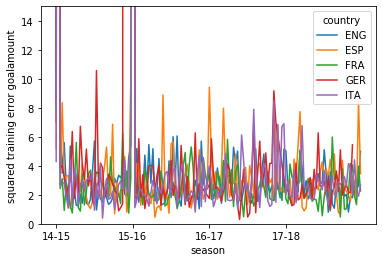

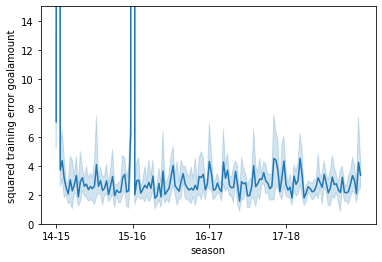

In [23]:
training_error_df = pd.read_csv('training_error_general.csv', sep=';')
sns.lineplot(data=training_error_df,
             x="season_matchnumber", y="squared_error_ga", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 15)
plt.xlabel("season")
plt.ylabel("squared training error goalamount")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_ga")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 15)
plt.xlabel("season")
plt.ylabel("squared training error goalamount")
plt.show()


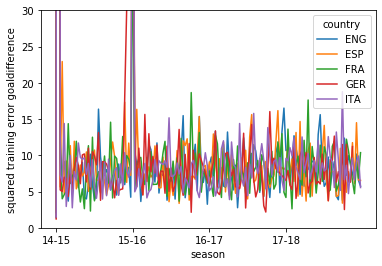

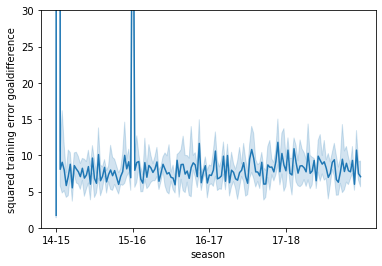

In [24]:
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_gd", hue="country")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
plt.xlabel("season")
plt.ylabel("squared training error goaldifference")
plt.show()
sns.lineplot(data=training_error_df, x="season_matchnumber",
             y="squared_error_gd")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.ylim(0, 30)
plt.xlabel("season")
plt.ylabel("squared training error goaldifference")
plt.show()


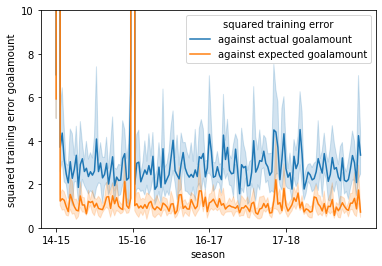

In [26]:
training_error_df["against actual goalamount"] = training_error_df["squared_error_ga"]
training_error_df["against expected goalamount"] = training_error_df["squared_error_xga"]
melted_df = training_error_df[["season_matchnumber", "against actual goalamount", "against expected goalamount"]].melt(
    "season_matchnumber", var_name="squared training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="squared training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("squared training error goalamount")
plt.ylim(0, 10)
plt.show()


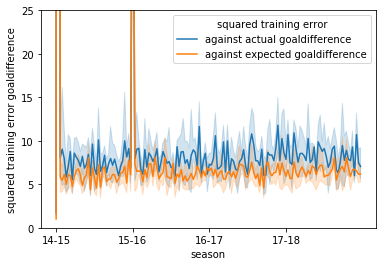

In [27]:
training_error_df["against actual goaldifference"] = training_error_df["squared_error_gd"]
training_error_df["against expected goaldifference"] = training_error_df["squared_error_xgd"]
melted_df = training_error_df[["season_matchnumber", "against actual goaldifference", "against expected goaldifference"]].melt(
    "season_matchnumber", var_name="squared training error", value_name="vals")

sns.lineplot(data=melted_df, x="season_matchnumber",
             y="vals", hue="squared training error")
plt.xticks(["14_1", "15_1", "16_1", "17_1"], [
           "14-15", "15-16", "16-17", "17-18"])
plt.xlabel("season")
plt.ylabel("squared training error goaldifference")
plt.ylim(0, 25)
plt.show()
